# Plasticity plotting

This notebook generates plots to visualize neural plasticity post-patching by comparing outputs of a model finetuned using baseline data for baseline and post-patching data. The inference data is expected to exist under settings.INFERENCE_DIR, organized by model name and fold. The notebook allows you to specify which subjects and conditions to visualize.

In [189]:
import os

import numpy as np
from core import plotting
from core import io
from core import settings
from core import utils
import matplotlib.pyplot as plt
from scipy.stats import sem, ttest_rel
import mne
from core import plot_data_processing as data_processor
from core.plot_data_processing import rename_chans_to_mne

In [190]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "huber_1001_all_data"
subjects = None # set to None to load all subjects
conditions = ["global"]  # set to None to load all conditions
trial_ids = None #[]  # set to None to load all trial ids
bands = None #[] # set to None to visualize all frequency bands
exclude_left_patched = True
exclude_right_patched_lefties = True # set to True to exclude subjects with left eye dominance and right patching
exclude_button_press = False # set to True to exclude button press trials (everything before STMD59)
analysis_window = "full" # set which time window to analyze, options are "analysis", "full", "button" and "reference"

In [191]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

# select subjects to exclude based on eye dominance, button press, and patching side
exclude_subjects = list(settings.EXCLUDED_SUBJECTS)
if exclude_left_patched:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT/"eye_dominance.csv"))
if exclude_right_patched_lefties:
    exclude_subjects.extend(utils.get_subjects_by_eye_dominance("left", settings.DATA_ROOT/"rightpatch_eye_dominance.csv")) # after STMD35, all patches were on the right eye, so exclude lefties
if exclude_button_press:
    press_subjects = [subj for subj in io.get_stored_subject_names(settings.DATA_ROOT) if utils.subject_paradigm(subj, settings.NO_PRESS_FROM_SUBJECT) == "press"]
    exclude_subjects.extend(press_subjects)
    print(exclude_subjects)

an_suffix = "window"
if analysis_window == "analysis":
    an_suffix+= "_analysis"
elif analysis_window == "full":
    an_suffix+= "_full"
elif analysis_window == "button":
    an_suffix+= "_button"
elif analysis_window == "reference":
    an_suffix+= "_reference"

excl_suffix = "excl"
if exclude_left_patched:
    excl_suffix+= "_left"
if exclude_right_patched_lefties:
    excl_suffix+= "_rightlefties"
if exclude_button_press:
    excl_suffix+= "_buttonpress"
if excl_suffix == "excl":
    excl_suffix = ""

# every plot of this notebook is saved under {model_name}/{conditions}/{plot type}/
plot_root = settings.PLOT_INFERENCE / model_name / ("_".join(conditions) if conditions else "all_conditions")


### Filter the inference data to only include the specified subjects, conditions, and trial ids

In [192]:

baseline_folds = []
baseline_merged = []
postpatch_folds = []
postpatch_merged = []

for i in range(1, 7):
    b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
    p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"


    b_fold_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects)
    baseline_folds.append(b_fold_trials)
    baseline_merged.extend(b_fold_trials)
    p_fold_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids, exclude_subjects=exclude_subjects)
    postpatch_folds.append(p_fold_trials)
    postpatch_merged.extend(p_fold_trials)


Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filteri

### Volatility-corrected MAE
MAE grows with the temporal variability (volatility) of the signal, so a pre/post change in volatility shows up as a change in MAE. `fill_corrected_maes` removes that dependence:
volatility and MAE are centered within each subject and session, one line per band is fitted on the centered trials of all subjects, and every trial's MAE is corrected to the mean baseline volatility:
`corrected MAE = MAE - slope * (volatility - mean baseline volatility)`.
The whole tensor and every channel are corrected separately (own slopes and reference volatility). The results are stored in `corrected_mae` / `corrected_mae_bandwise` of `trial.metrics` and `trial.channel_metrics`.

In [193]:
slopes, channel_slopes = data_processor.fill_corrected_maes(baseline_merged, postpatch_merged, bands)

print("Global slopes (MAE per unit volatility):")
for band, slope in slopes.items():
    ch_values = [channel_slopes[ch][band] for ch in channel_slopes]
    print(f"  {band:16s} {slope:.3f}   channel slopes: {min(ch_values):.3f} - {max(ch_values):.3f}")


Global slopes (MAE per unit volatility):
  all bands        0.569   channel slopes: 0.320 - 0.427
  delta (2-4Hz)    0.781   channel slopes: 0.356 - 0.519
  theta (4-8Hz)    0.367   channel slopes: 0.156 - 0.256
  alpha (8-12Hz)   0.217   channel slopes: 0.133 - 0.191
  beta (12-30Hz)   0.297   channel slopes: 0.153 - 0.185
  gamma (30-60Hz)  0.488   channel slopes: 0.342 - 0.380


# Plotting the difference between baseline and post-patching performance

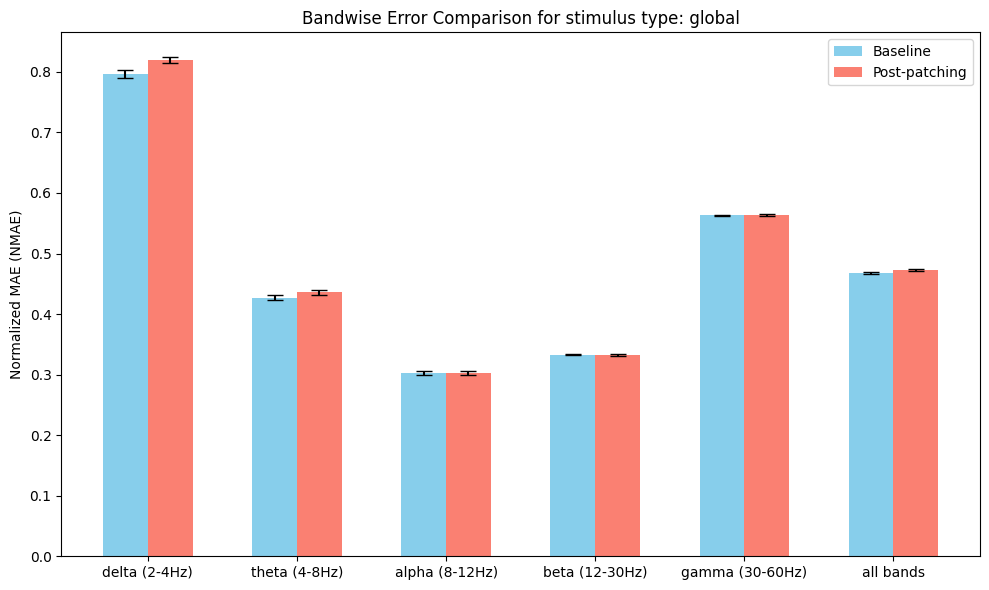

In [194]:



baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="nmae", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="nmae", bands=settings.FREQ_BANDS)

title = f'Bandwise Error Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels, title=title)
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_comparison", default_name=f"error_{an_suffix}_{excl_suffix}")


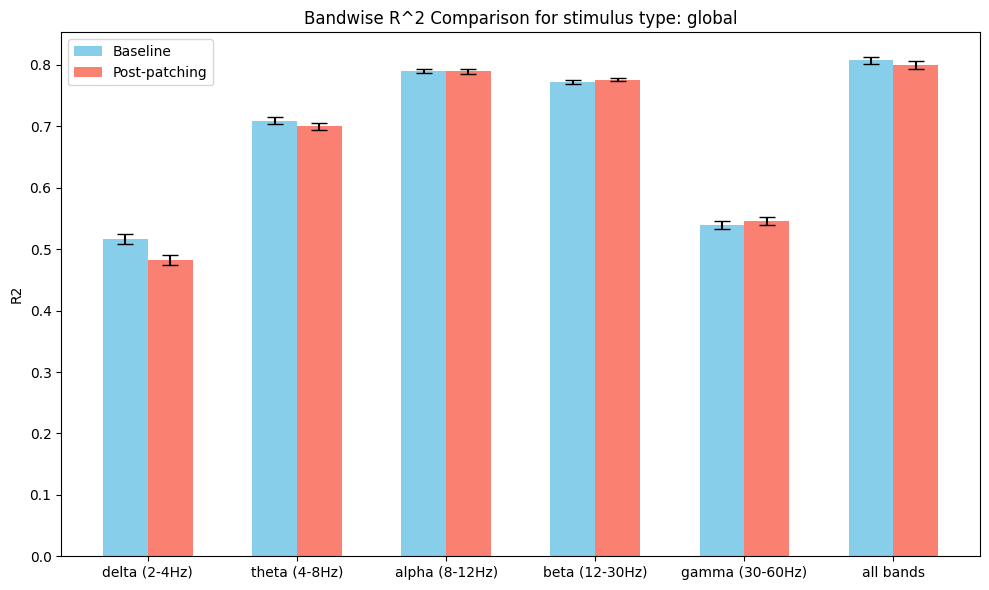

In [195]:


baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged, metric_name="r2_bandwise", bands=settings.FREQ_BANDS)

title = f'Bandwise R^2 Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
y_label = "R2"

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels, title=title, y_label=y_label)
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_comparison", default_name=f"r2_error_{an_suffix}_{excl_suffix}")


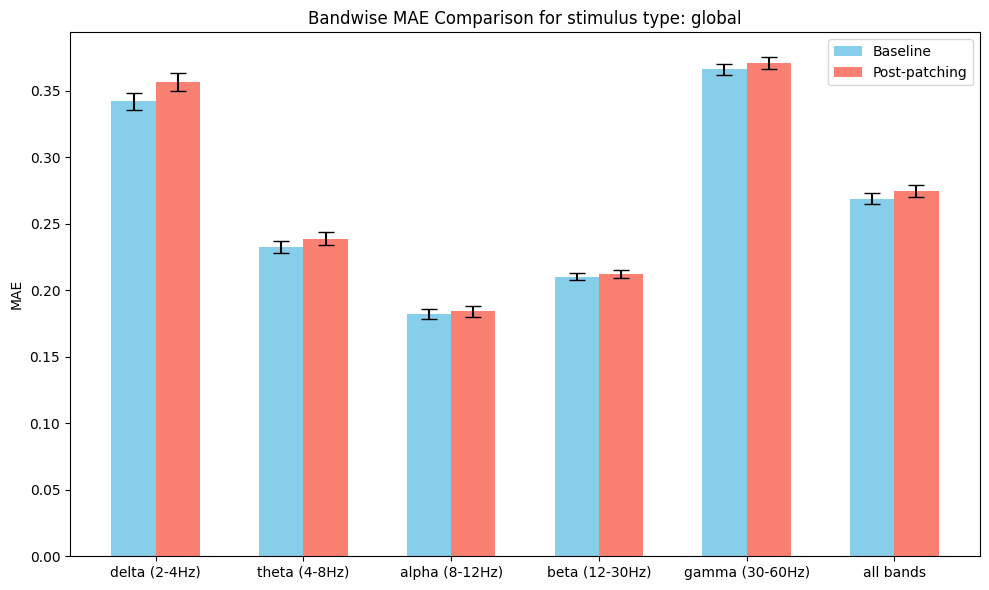

In [196]:
# Plotting the difference between baseline and post-patching performance


baseline_means, baseline_sems = data_processor.get_subjectwise_metric_mean(baseline_merged,
                                                                           metric_name="mae_bandwise",
                                                                           bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems = data_processor.get_subjectwise_metric_mean(postpatch_merged,
                                                                              metric_name="mae_bandwise",
                                                                              bands=settings.FREQ_BANDS)

title = f'Bandwise MAE Comparison for stimulus type: {", ".join(conditions)}'
width = 0.3
ylabel = "MAE"
ylim = None

means = [baseline_means.values(), postpatch_means.values()]
sems = [baseline_sems.values(), postpatch_sems.values()]
comparison_labels = ["Baseline", "Post-patching"]

fig, ax = plotting.plot_grouped_bar(x_text=baseline_means.keys(), width=width, means=means, sems=sems, labels=comparison_labels,
                                    title=title, y_label=ylabel, ylim=ylim)

plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison",
                     default_name=f"error_{an_suffix}_{excl_suffix}")

## Single channel comparison viewer

In [197]:
input_metrics = []

input_metrics.append(data_processor.get_channel_viewer_metrics(baseline_merged, ["nmae", "nmae_bandwise"], ))
input_metrics.append(data_processor.get_channel_viewer_metrics(postpatch_merged, ["nmae", "nmae_bandwise"], ))

In [198]:

input_data = [baseline_merged, postpatch_merged]
styling_params = {
        "param_text": "",
        #"suptitle": f"Single channel reconstruction comparison for stimulus type: {', '.join(conditions)}",
        "suptitle": f"Single channel reconstruction comparison for stimulus type: ",
        "apply_log": False,
        "target_mode": "wavelet",
}
save_dir = plot_root / "single_channel_comparison"
plotting.single_channel_viewer(input_data, input_metrics, n_chans=settings.N_CHANNELS, styling_params=styling_params, save_dir=save_dir, bands=settings.FREQ_BANDS.keys(), freqs=settings.FREQS, an_suffix=an_suffix, excl_suffix=excl_suffix)

## Topomaps of all bands and bandwise error for given condition

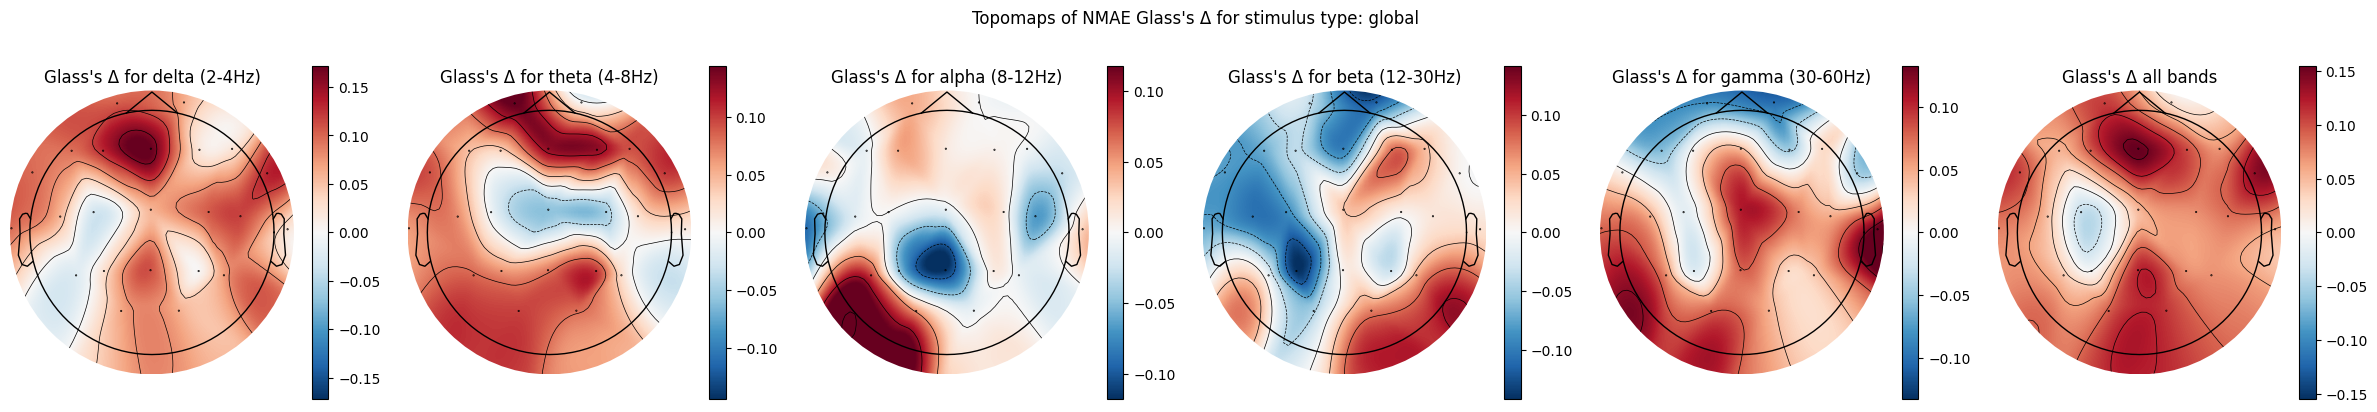

In [199]:


nmae_bw_b, _, std_bw_b = data_processor.get_channel_bandwise_metric_stats(baseline_merged, "nmae_bandwise", bands=settings.FREQ_BANDS)
nmae_bw_p, _, std_bw_p = data_processor.get_channel_bandwise_metric_stats(postpatch_merged, "nmae_bandwise", bands=settings.FREQ_BANDS)
glass_d_ch_bw = data_processor.calc_channel_bandwise_glass_delta(nmae_bw_b, nmae_bw_p, std_bw_b)

nmae_b, _, std_b = data_processor.get_channel_metric_stats(baseline_merged, "nmae")
nmae_p, _, std_p = data_processor.get_channel_metric_stats(postpatch_merged, "nmae")

glass_d_ch_bw["all_bands"] = data_processor.calc_channel_glass_delta(nmae_b, nmae_p, std_b)


ch_names = [settings.CHORDER_STANDARD[i] for i in range(settings.N_CHANNELS)]

rename_chans_to_mne(ch_names)

info = mne.create_info(ch_names=ch_names, sfreq=settings.RSFREQ, ch_types='eeg') # sfreq is required but not relevant for static topomap
montage = mne.channels.make_standard_montage('standard_1005')
info.set_montage(montage)

# create 1x6 subplot for all bands MAE and each frequency band's MAE with topomap of Glass's delta values
fig, axes = plt.subplots(1, len(glass_d_ch_bw), figsize=(24, 4))

for i, (band, vals) in enumerate(glass_d_ch_bw.items()):

    max_val = max(np.abs(vals))
    vlim = (-max_val, max_val)
    im, _ = mne.viz.plot_topomap(vals, info, axes=axes[i], show=False, vlim=vlim, cmap="RdBu_r")
    if band == "all_bands":
        axes[i].set_title(f"Glass's Δ all bands")
    else:
        axes[i].set_title(f"Glass's Δ for {band}")
    fig.colorbar(im, ax=axes[i])
plt.suptitle(f"Topomaps of NMAE Glass's Δ for stimulus type: {', '.join(conditions)}", y=1.02)
plotting.save_button(fig, save_dir=plot_root / "bandwise_topomaps", default_name=f"nmae_topomaps_{an_suffix}_{excl_suffix}")

plt.tight_layout()
plt.show()


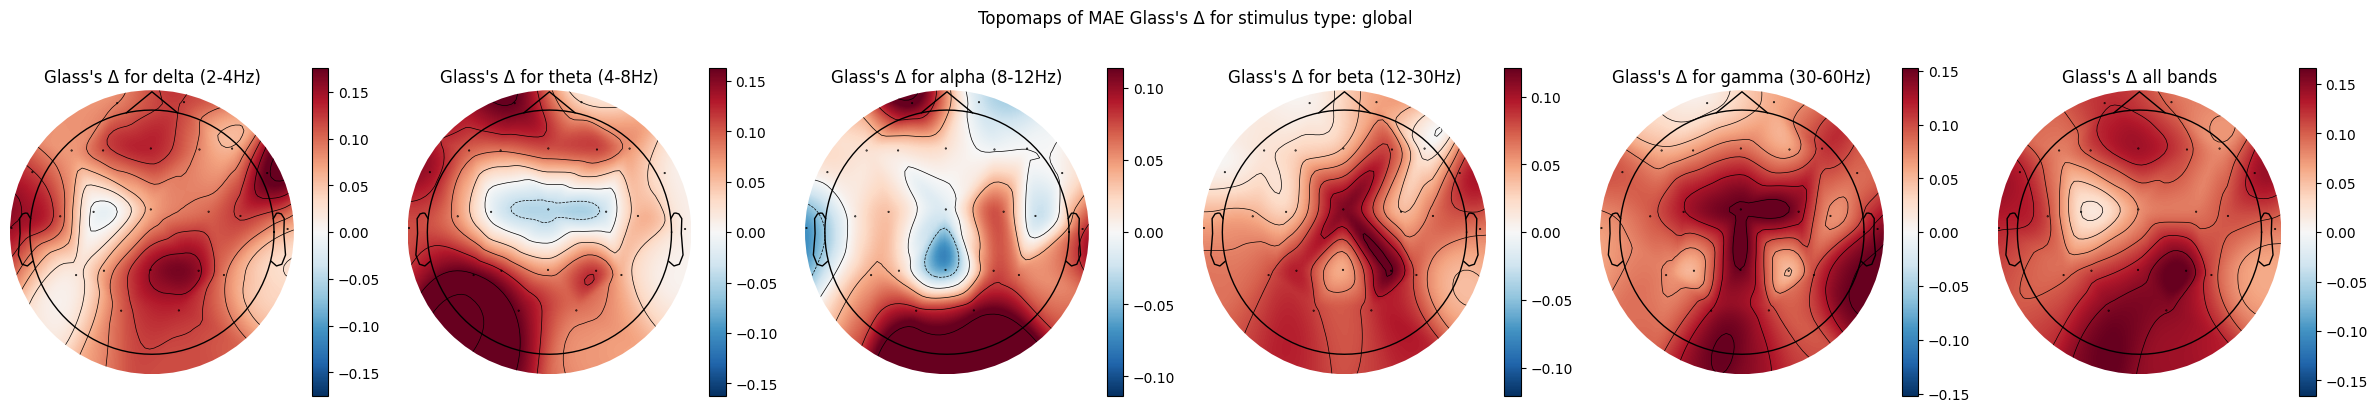

In [200]:


mae_bw_b, _, std_bw_b = data_processor.get_channel_bandwise_metric_stats(baseline_merged, "mae_bandwise", bands=settings.FREQ_BANDS)
mae_bw_p, _, std_bw_p = data_processor.get_channel_bandwise_metric_stats(postpatch_merged, "mae_bandwise", bands=settings.FREQ_BANDS)
mae_glass_d_ch_bw = data_processor.calc_channel_bandwise_glass_delta(mae_bw_b, mae_bw_p, std_bw_b)

mae_b, _, std_b = data_processor.get_channel_metric_stats(baseline_merged, "mae")
mae_p, _, std_p = data_processor.get_channel_metric_stats(postpatch_merged, "mae")

mae_glass_d_ch_bw["all_bands"] = data_processor.calc_channel_glass_delta(mae_b, mae_p, std_b)


ch_names = [settings.CHORDER_STANDARD[i] for i in range(settings.N_CHANNELS)]

rename_chans_to_mne(ch_names)

info = mne.create_info(ch_names=ch_names, sfreq=settings.RSFREQ, ch_types='eeg') # sfreq is required but not relevant for static topomap
montage = mne.channels.make_standard_montage('standard_1005')
info.set_montage(montage)

# create 1x6 subplot for all bands MAE and each frequency band's MAE with topomap of Glass's delta values
fig, axes = plt.subplots(1, len(mae_glass_d_ch_bw), figsize=(24, 4))

for i, (band, vals) in enumerate(mae_glass_d_ch_bw.items()):

    max_val = max(np.abs(vals))
    vlim = (-max_val, max_val)
    im, _ = mne.viz.plot_topomap(vals, info, axes=axes[i], show=False, vlim=vlim, cmap="RdBu_r")
    if band == "all_bands":
        axes[i].set_title(f"Glass's Δ all bands")
    else:
        axes[i].set_title(f"Glass's Δ for {band}")
    fig.colorbar(im, ax=axes[i])
plt.suptitle(f"Topomaps of MAE Glass's Δ for stimulus type: {', '.join(conditions)}", y=1.02)
plotting.save_button(fig, save_dir=plot_root / "bandwise_topomaps", default_name=f"mae_topomaps_{an_suffix}_{excl_suffix}")

plt.tight_layout()
plt.show()


## Plotting average power of trials where reconstruction NMAE was smaller for post-patching than baseline

In [201]:
# for band, ch_data in glass_d_ch_bw.items():
#     for ch_id, delta in enumerate(ch_data):
#         if delta < 0:
#             baseline_trials = [trial for trial in baseline_merged]
#             postpatch_trials = [trial for trial in postpatch_merged if trial.metrics.nmae_bandwise[band][ch_id] < trial.metrics.nmae_bandwise[band][ch_id]]


## plotting bandwise amplitude changes pre- and post-patching

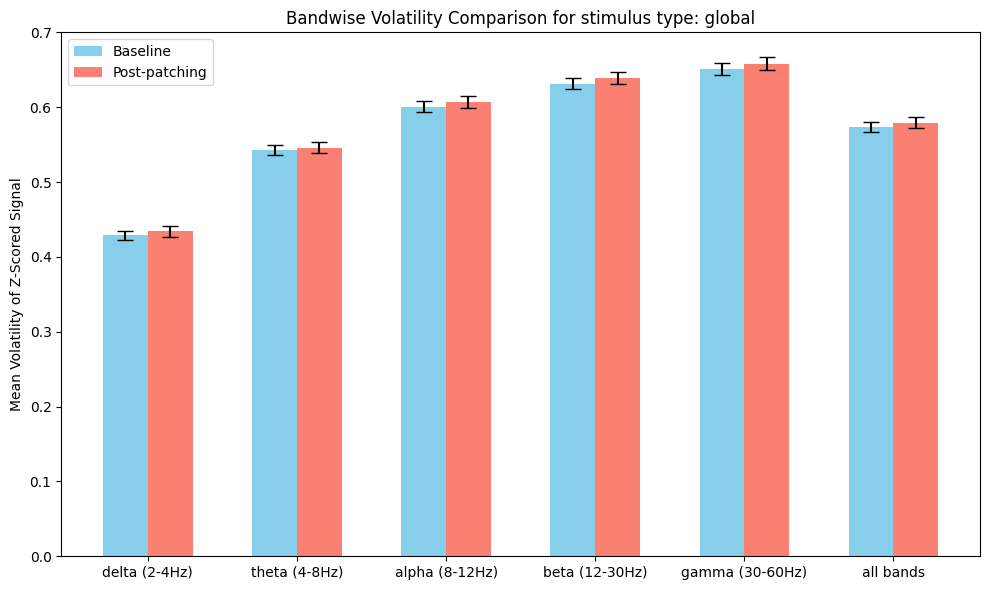

In [202]:
ampl_bw_b, sem_bw_b= data_processor.get_subjectwise_metric_mean(baseline_merged, bands=bands, metric_name="signal_volatility_bandwise")
ampl_bw_p, sem_bw_p = data_processor.get_subjectwise_metric_mean(postpatch_merged, bands=bands, metric_name="signal_volatility_bandwise")



x_text = list(ampl_bw_b.keys())



fig, ax = plt.subplots(figsize=(10, 6))
width = 0.3
x = np.arange(len(x_text))
title = f'Bandwise Volatility Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, ampl_bw_b.values(), width=width, yerr=sem_bw_b.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, ampl_bw_p.values(), width=width, yerr=sem_bw_p.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(x_text)

# Formatting
ax.set_ylabel('Mean Volatility of Z-Scored Signal')
ax.set_title(title)
ax.legend()

plotting.save_button(fig, save_dir=plot_root / "bandwise_volatility", default_name=f"bw_vols_{an_suffix}_{excl_suffix}")

plt.tight_layout()
plt.show()

## Subject-wise gamma NMAE comparison pre- and post-patching

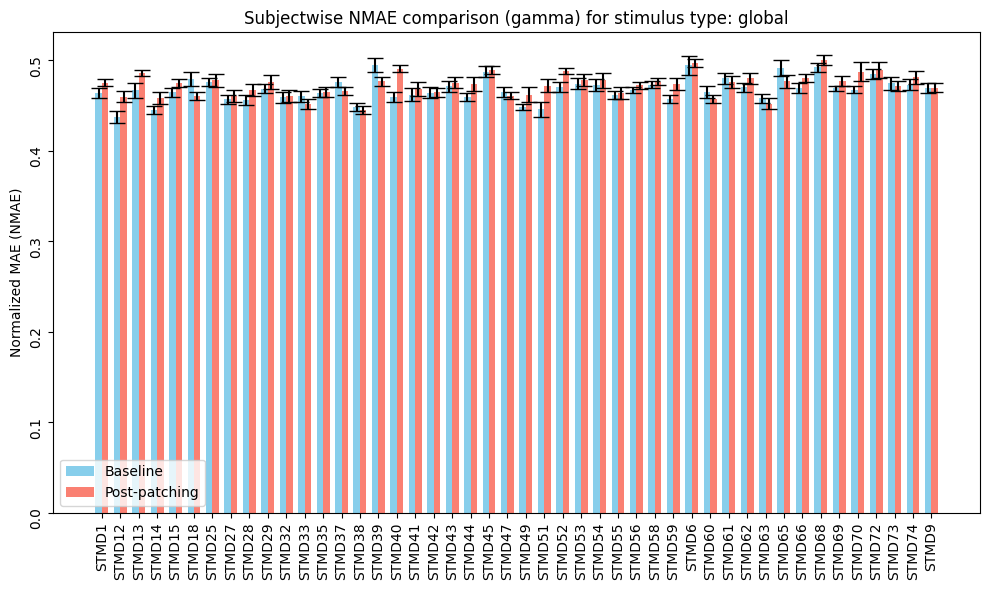

In [203]:
subjectwise_nmae_b, subjectwise_nmae_sem_b = data_processor.calc_subjectwise_metric_stats(baseline_merged, ["gamma (30-60Hz)"], metric="nmae")
subjectwise_nmae_p, subjectwise_nmae_sem_p = data_processor.calc_subjectwise_metric_stats(postpatch_merged, ["gamma (30-60Hz)"], metric="nmae")

band = "all bands"

sb_baseline_nmae = {s: subjectwise_nmae_b[s][band] for s in sorted(subjectwise_nmae_b)}
sb_baseline_sem  = {s: subjectwise_nmae_sem_b[s][band] for s in sorted(subjectwise_nmae_b)}
sb_postpatch_nmae = {s: subjectwise_nmae_p[s][band] for s in sorted(subjectwise_nmae_b)}
sb_postpatch_sem  = {s: subjectwise_nmae_sem_p[s][band] for s in sorted(subjectwise_nmae_b)}

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(subjectwise_nmae_b.keys()))
title = f'Subjectwise NMAE comparison (gamma) for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, sb_baseline_nmae.values(), width=width, yerr=sb_baseline_sem.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, sb_postpatch_nmae.values(), width=width, yerr=sb_postpatch_sem.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.tick_params(labelrotation=90)
ax.set_xticklabels(sb_baseline_nmae.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(title)
ax.legend()
plotting.save_button(fig, save_dir=plot_root / "subjectwise_e_comparison", default_name=f"nmae_subjectwise_gamma_{an_suffix}_{excl_suffix}")
plt.tight_layout()
plt.show()


## Plotting NMAE distribution of pre and post-patching trials

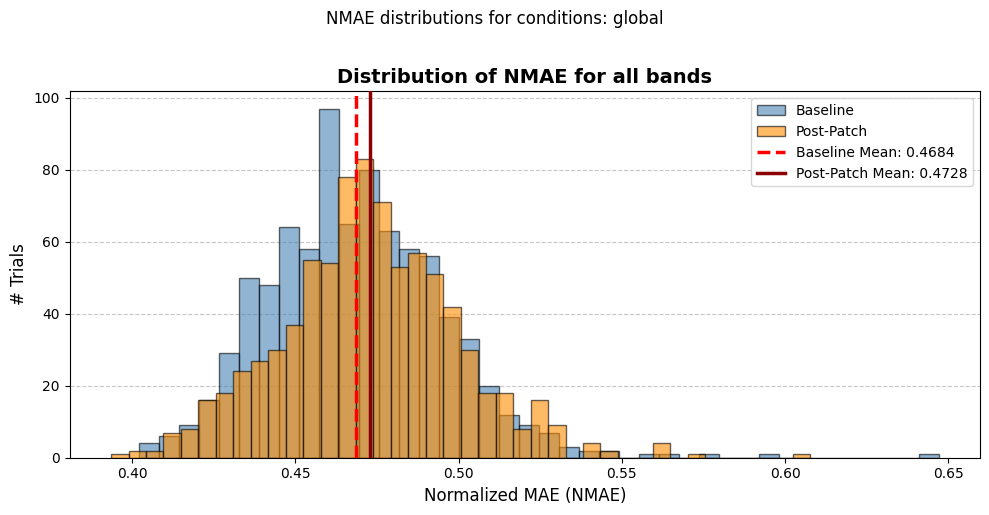

In [204]:
pre_nmaes = data_processor.extract_metric(baseline_merged, "nmae")
post_nmaes = data_processor.extract_metric(postpatch_merged, "nmae")

save_dir = plot_root / "nmae_dist_comparison"
plotting.distribution_viewer({"all bands": pre_nmaes}, {"all bands": post_nmaes}, title=f'NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"nmae_dist_all_bands_{an_suffix}_{excl_suffix}")



## Plotting bandwise NMAE distribution of pre and post-patching trials

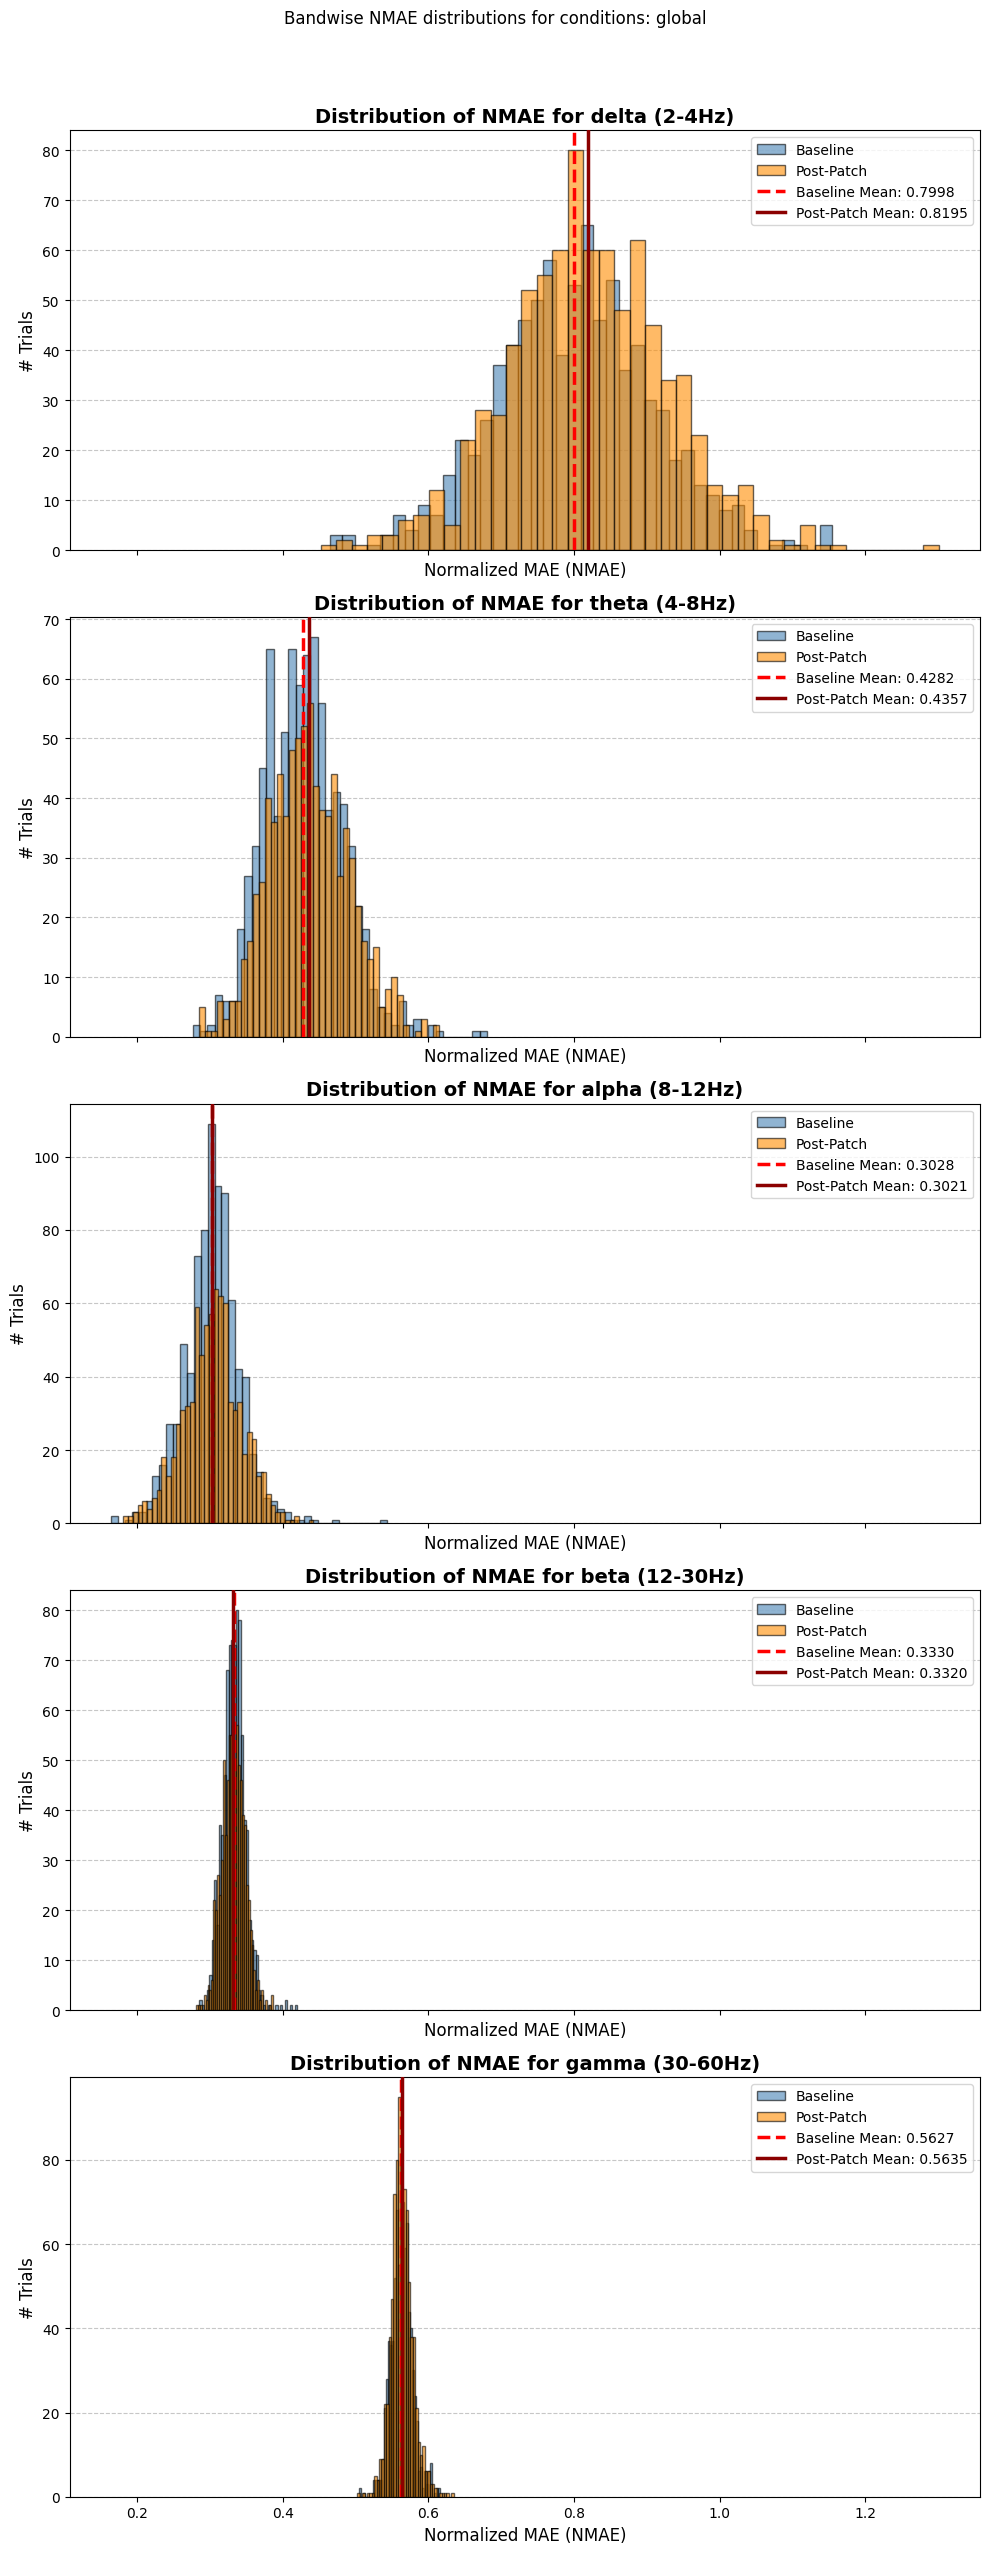

In [205]:
pre_nmaes_bw = data_processor.extract_metric(baseline_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)
post_nmaes_bw = data_processor.extract_metric(postpatch_merged, "nmae_bandwise", bandwise=True, bands=settings.FREQ_BANDS)

save_dir = plot_root / "nmae_dist_comparison"
plotting.distribution_viewer(pre_nmaes_bw, post_nmaes_bw, title=f'Bandwise NMAE distributions for conditions: {", ".join(conditions)}', save_dir=save_dir, save_name = f"nmae_dist_bandwise_{an_suffix}_{excl_suffix}")



## Correlation of signal volatility and model error (NMAE vs MAE)
Trials of both sessions are pooled. Trials with higher volatility have higher MAE, a flat NMAE slope shows the normalization removes that dependence.

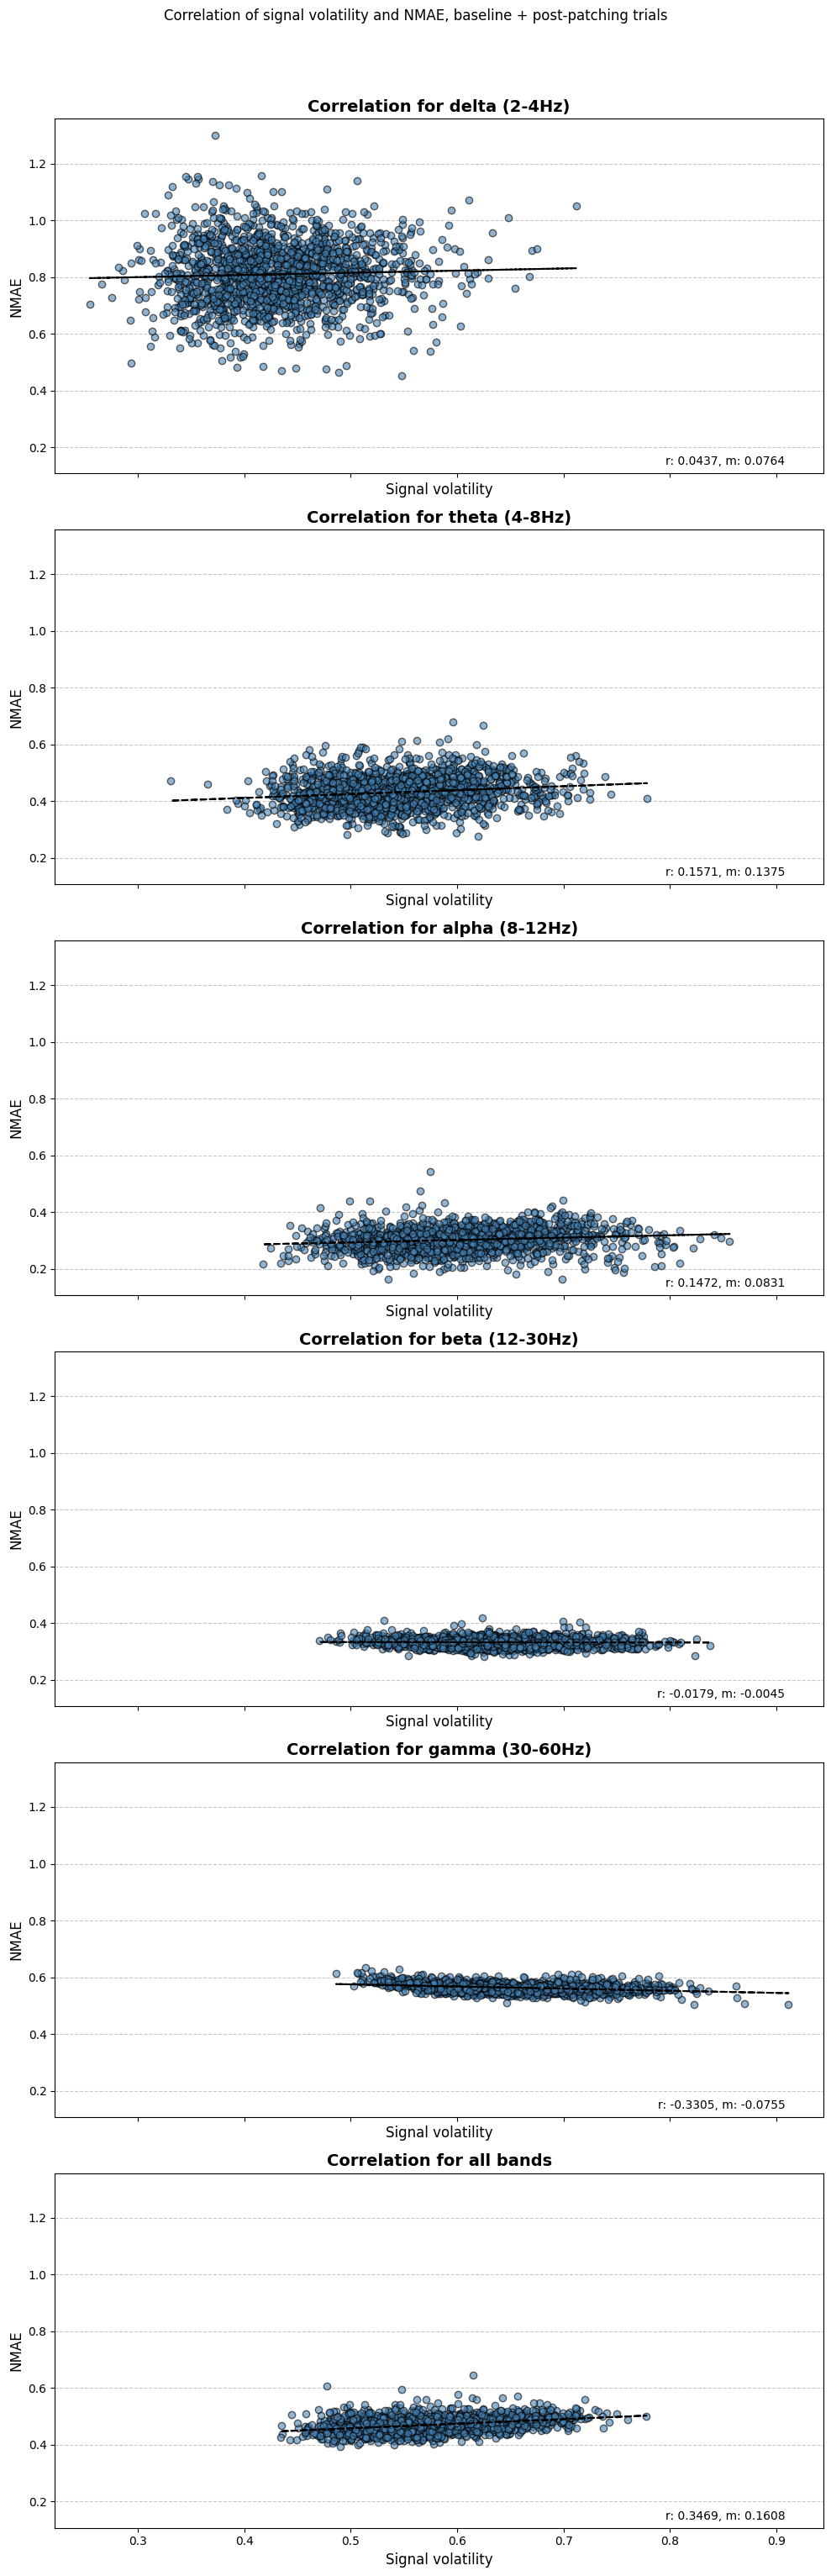

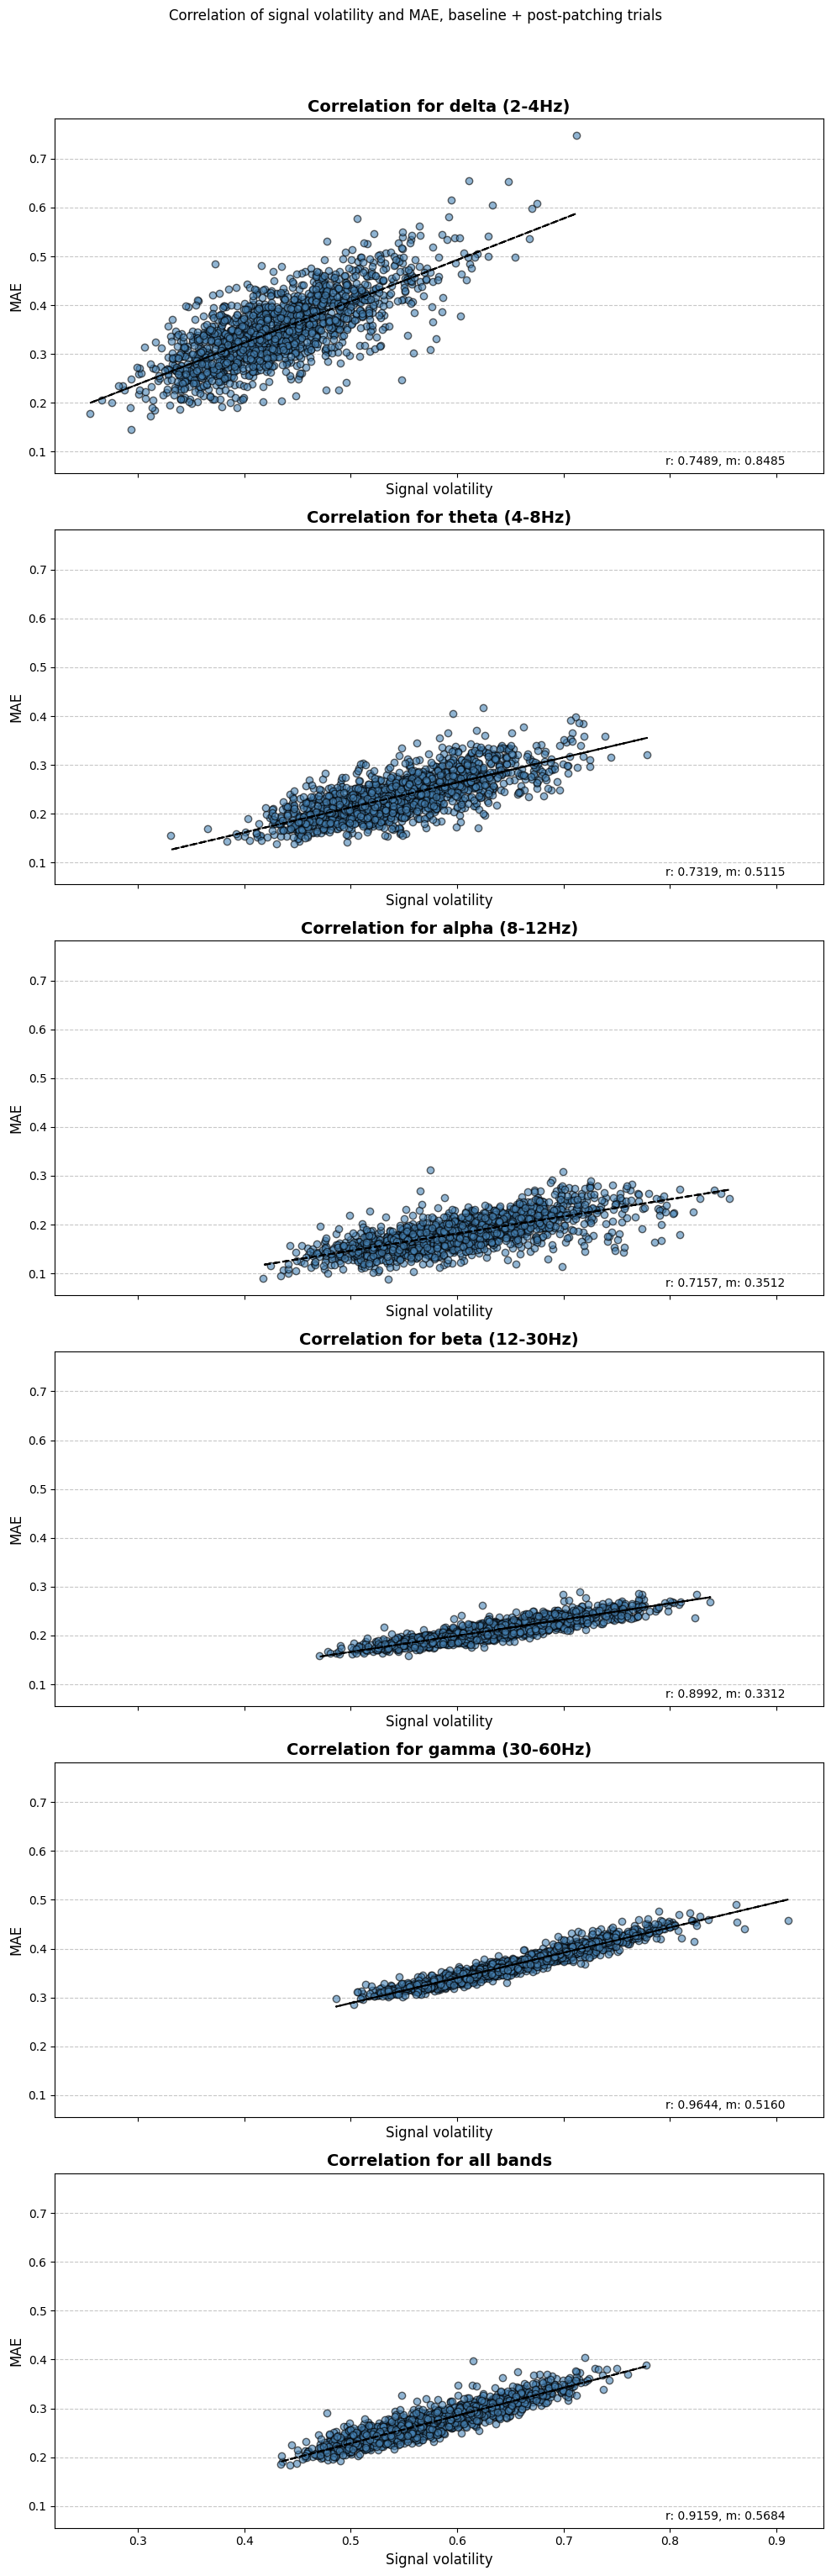

In [206]:
all_trials = baseline_merged + postpatch_merged
vols = data_processor.extract_metric(all_trials, "signal_volatility_bandwise", bands, bandwise=True)
vols["all bands"] = data_processor.extract_metric(all_trials, "signal_volatility")

for metric, label in [("nmae", "NMAE"), ("mae", "MAE")]:
    errors = data_processor.extract_metric(all_trials, f"{metric}_bandwise", bands, bandwise=True)
    errors["all bands"] = data_processor.extract_metric(all_trials, metric)
    plotting.correlation_plot(x=vols, y=errors, title=f'Correlation of signal volatility and {label}, baseline + post-patching trials',
                              xlabel='Signal volatility', ylabel=label,
                              save_dir=plot_root / "correlation_plots", save_name=f"{metric}_correlation_{an_suffix}_{excl_suffix}")


## Effect of the volatility correction (MAE, NMAE, corrected MAE)

### Volatility vs. error before and after the correction
Pooled trials of both sessions, with a separate fitted line per session. MAE grows with volatility, with the same slope in both sessions. NMAE divides by volatility, the corrected MAE subtracts the fitted within-subject dependence. Each panel has its own y scale, as the metrics have different units.

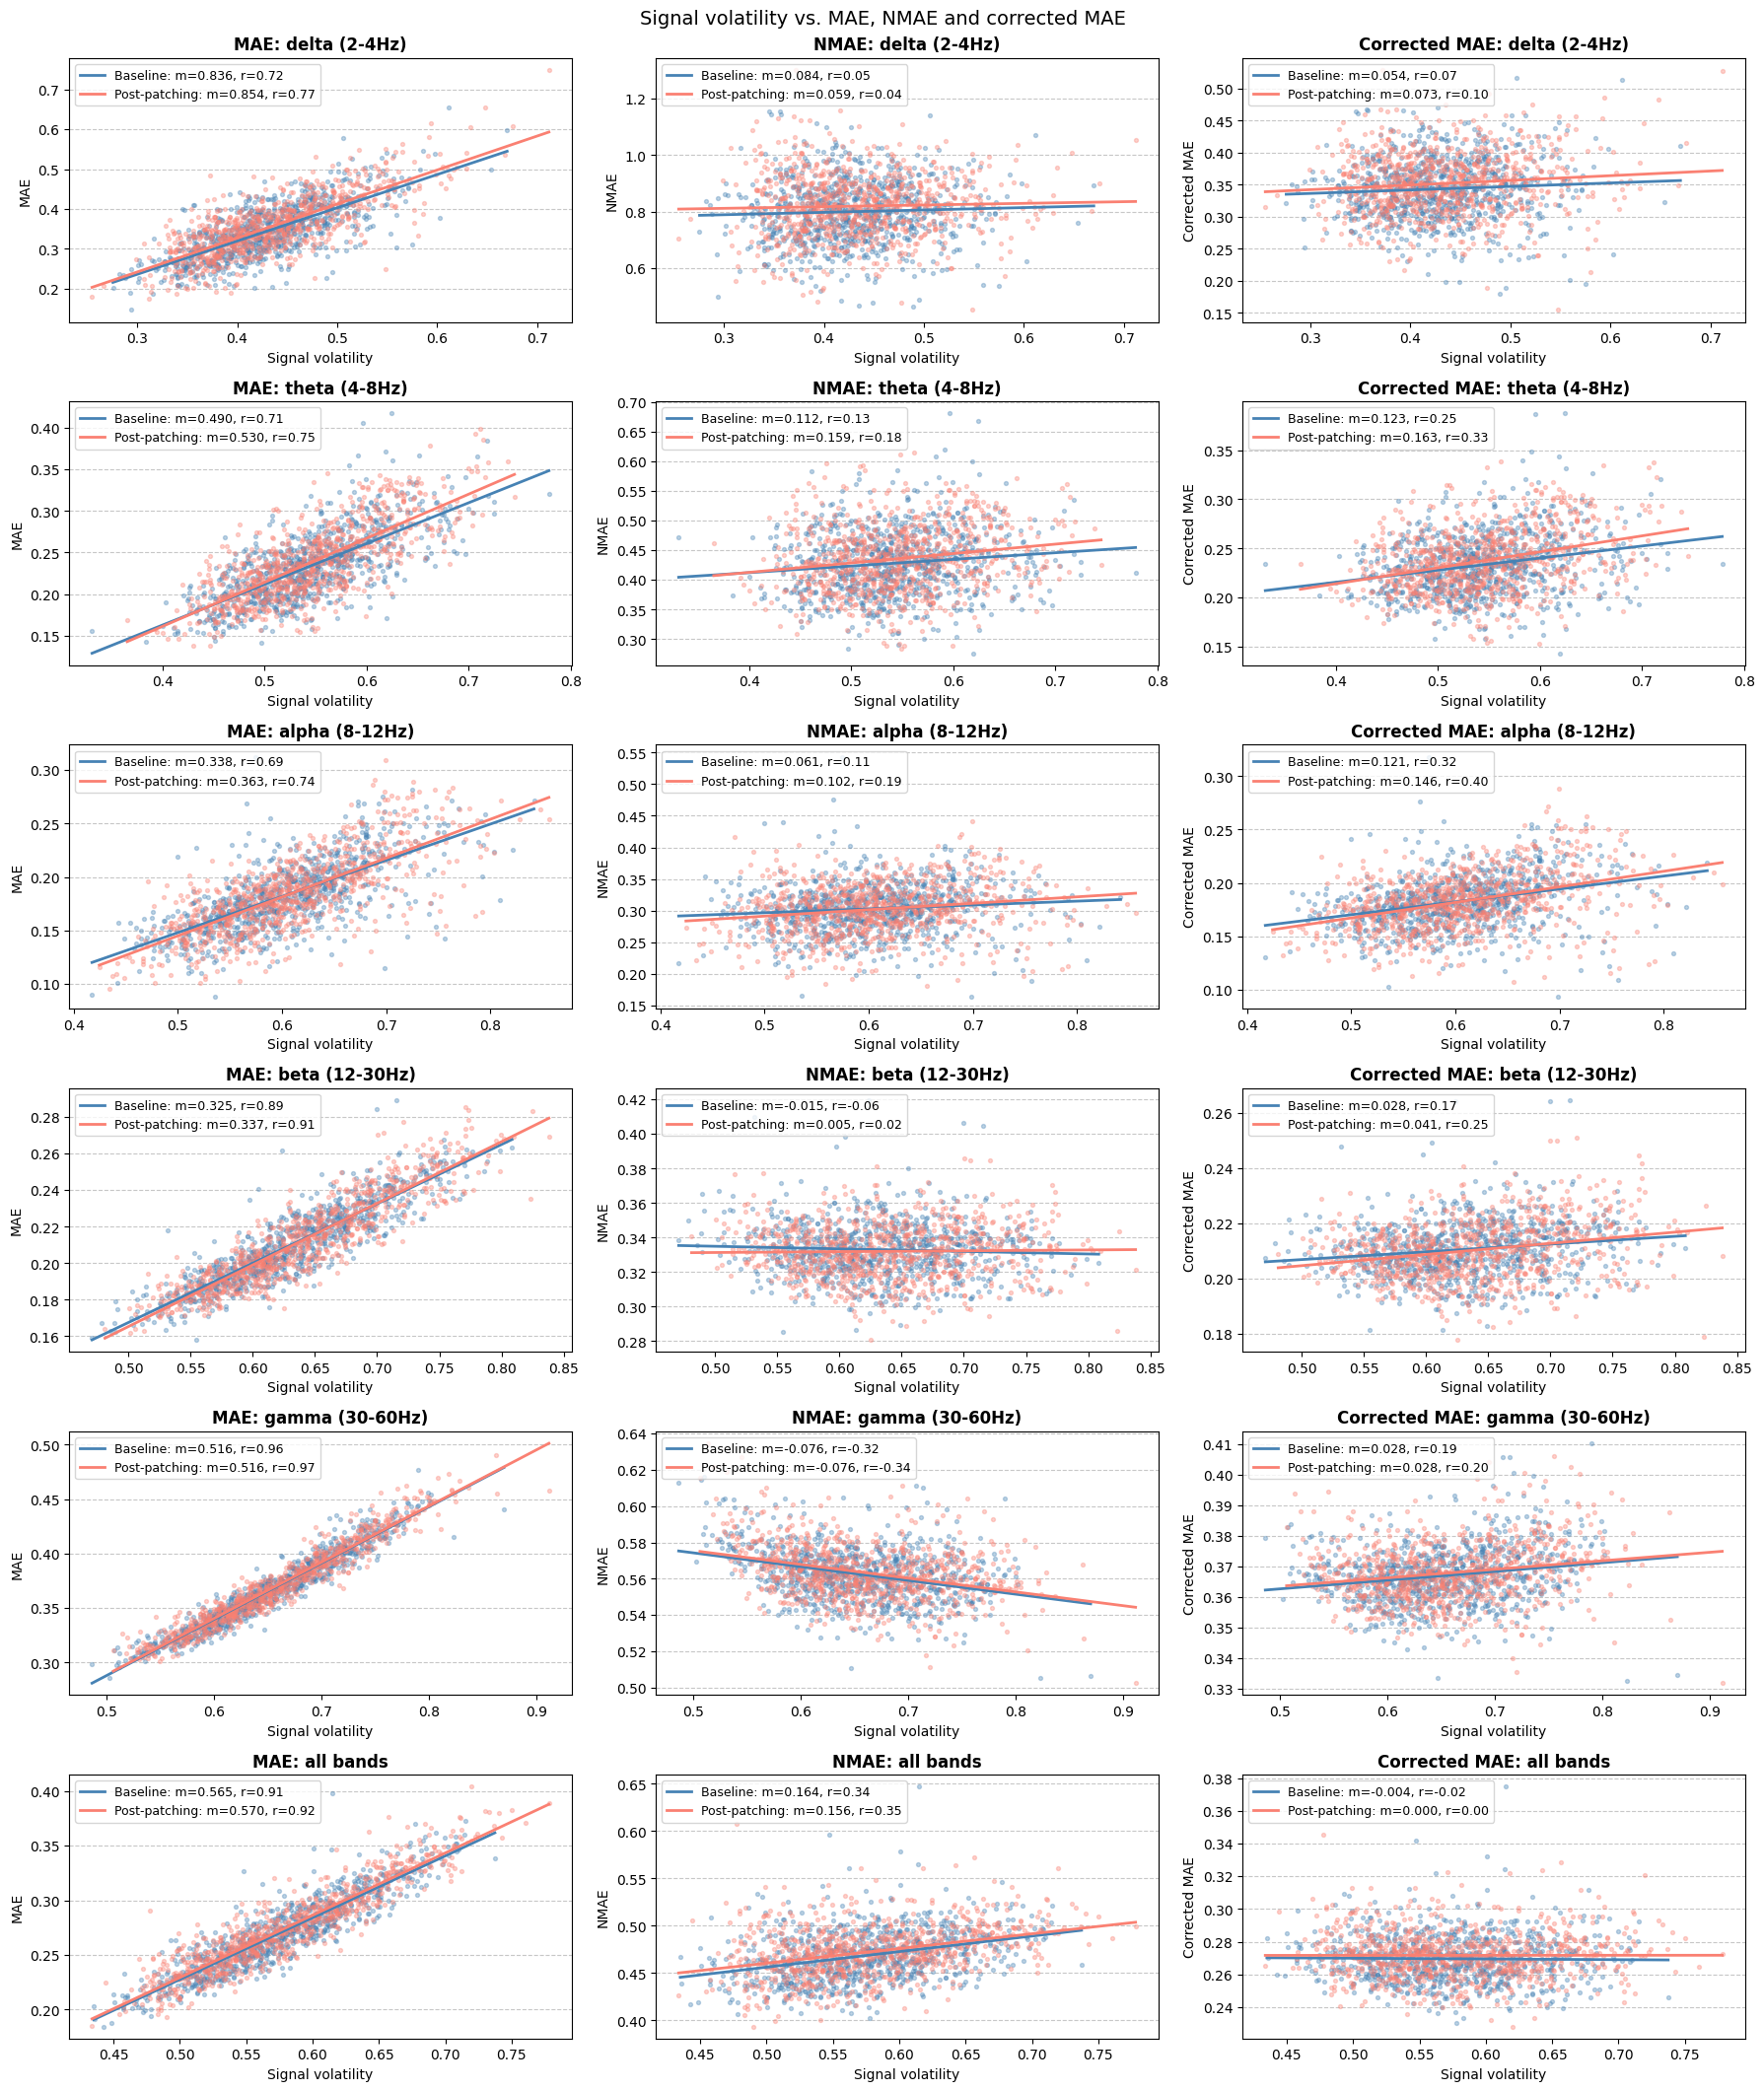

In [207]:
metrics_to_compare = {"MAE": "mae", "NMAE": "nmae", "Corrected MAE": "corrected_mae"}
band_keys = [*bands, "all bands"]

vols, errors = {}, {label: {} for label in metrics_to_compare}
for session, trials in [("Baseline", baseline_merged), ("Post-patching", postpatch_merged)]:
    vols[session] = data_processor.extract_metric(trials, "signal_volatility_bandwise", bands, bandwise=True)
    vols[session]["all bands"] = data_processor.extract_metric(trials, "signal_volatility")
    for label, metric in metrics_to_compare.items():
        errors[label][session] = data_processor.extract_metric(trials, f"{metric}_bandwise", bands, bandwise=True)
        errors[label][session]["all bands"] = data_processor.extract_metric(trials, metric)

plotting.session_correlation_plot(x_by_session=vols, y_by_metric=errors, xlabel="Signal volatility", sharey=False,
                                  title="Signal volatility vs. MAE, NMAE and corrected MAE",
                                  save_dir=plot_root / "correlation_plots", save_name=f"mae_correction_correlation_{an_suffix}_{excl_suffix}")


### Change of MAE, NMAE and corrected MAE after patching
Subject means per session. Bars show the mean of the subject differences (post-patching - baseline) ± SEM, in % of the mean baseline value of each metric, so the three metrics are comparable. The p-values are paired t-tests on the subject means.

band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
delta (2-4Hz)    |             +4.16  0.002 |             +2.79  0.001 |             +2.84  0.001
theta (4-8Hz)    |             +2.69  0.016 |             +2.05  0.004 |             +2.23  0.003
alpha (8-12Hz)   |             +1.16  0.322 |             +0.08  0.907 |             +0.46  0.576
beta (12-30Hz)   |             +0.92  0.254 |             -0.31  0.226 |             -0.15  0.619
gamma (30-60Hz)  |             +1.20  0.071 |             +0.09  0.523 |             +0.23  0.115
all bands        |             +2.15  0.020 |             +1.06  0.003 |             +0.87  0.003


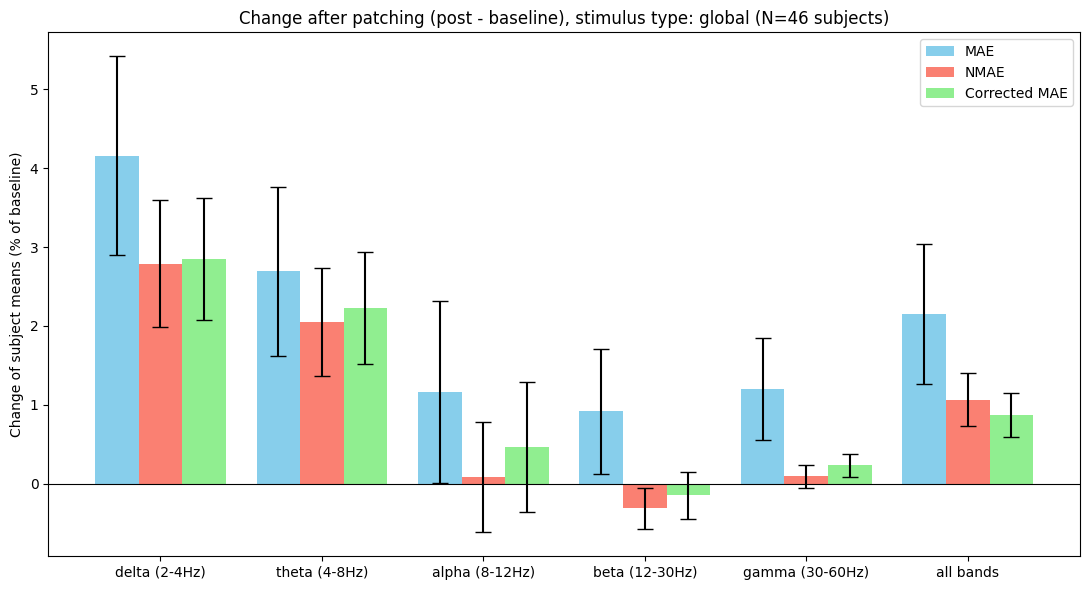

In [208]:
# raw change of the subject means per metric: mean ± SEM of the subject differences in % of the mean baseline, paired t-test
raw_changes = {}
for label, metric in metrics_to_compare.items():
    b_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, metric)
    p_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, metric)
    subjects = [s for s in b_means if s in p_means]
    pre = np.array([[b_means[s][b] for b in band_keys] for s in subjects])
    post = np.array([[p_means[s][b] for b in band_keys] for s in subjects])
    scale = 100 / pre.mean(axis=0)
    raw_changes[label] = ((post - pre).mean(axis=0) * scale, sem(post - pre) * scale, ttest_rel(post, pre).pvalue)

print(f"{'band':16s}" + "".join(f" | {label + ' %':>17s} {'p':>6s}" for label in raw_changes))
for i, band in enumerate(band_keys):
    print(f"{band:16s}" + "".join(f" | {changes[i]:+17.2f} {ps[i]:6.3f}" for changes, _, ps in raw_changes.values()))

fig, ax = plt.subplots(figsize=(11, 6))
plotting.plot_grouped_bar(x_text=band_keys, width=0.27, means=[changes for changes, _, _ in raw_changes.values()],
                          sems=[sems for _, sems, _ in raw_changes.values()], labels=list(raw_changes.keys()),
                          title=f'Change after patching (post - baseline), stimulus type: {", ".join(conditions)}',
                          y_label="Change of subject means (% of baseline)", n_text=f"N={len(subjects)} subjects", ax=ax, fig=fig)
ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plotting.save_button(fig, save_dir=plot_root / "bandwise_e_mae_comparison", default_name=f"mae_correction_difference_{an_suffix}_{excl_suffix}")
plt.show()


## Subject-level volatility adjustment
The baseline vs. post-patching comparison runs on subject means, so the volatility dependence is removed at that level:
for every band, one line is fitted on the subjects' metric change (post - baseline) against their volatility change.
The adjusted change of a subject is its change minus `slope * volatility change`, i.e. the change it would have without a volatility change.
The mean of the adjusted changes equals the intercept of the fit, which is tested for the adjusted effect.

### Subject changes vs. volatility change, before and after the adjustment
One point per subject, one figure per metric. Left: raw changes with the fitted line, showing how much the metric still depends on the volatility change.
Right: adjusted changes. The right line is flat by construction, so it illustrates the adjustment rather than validating it.

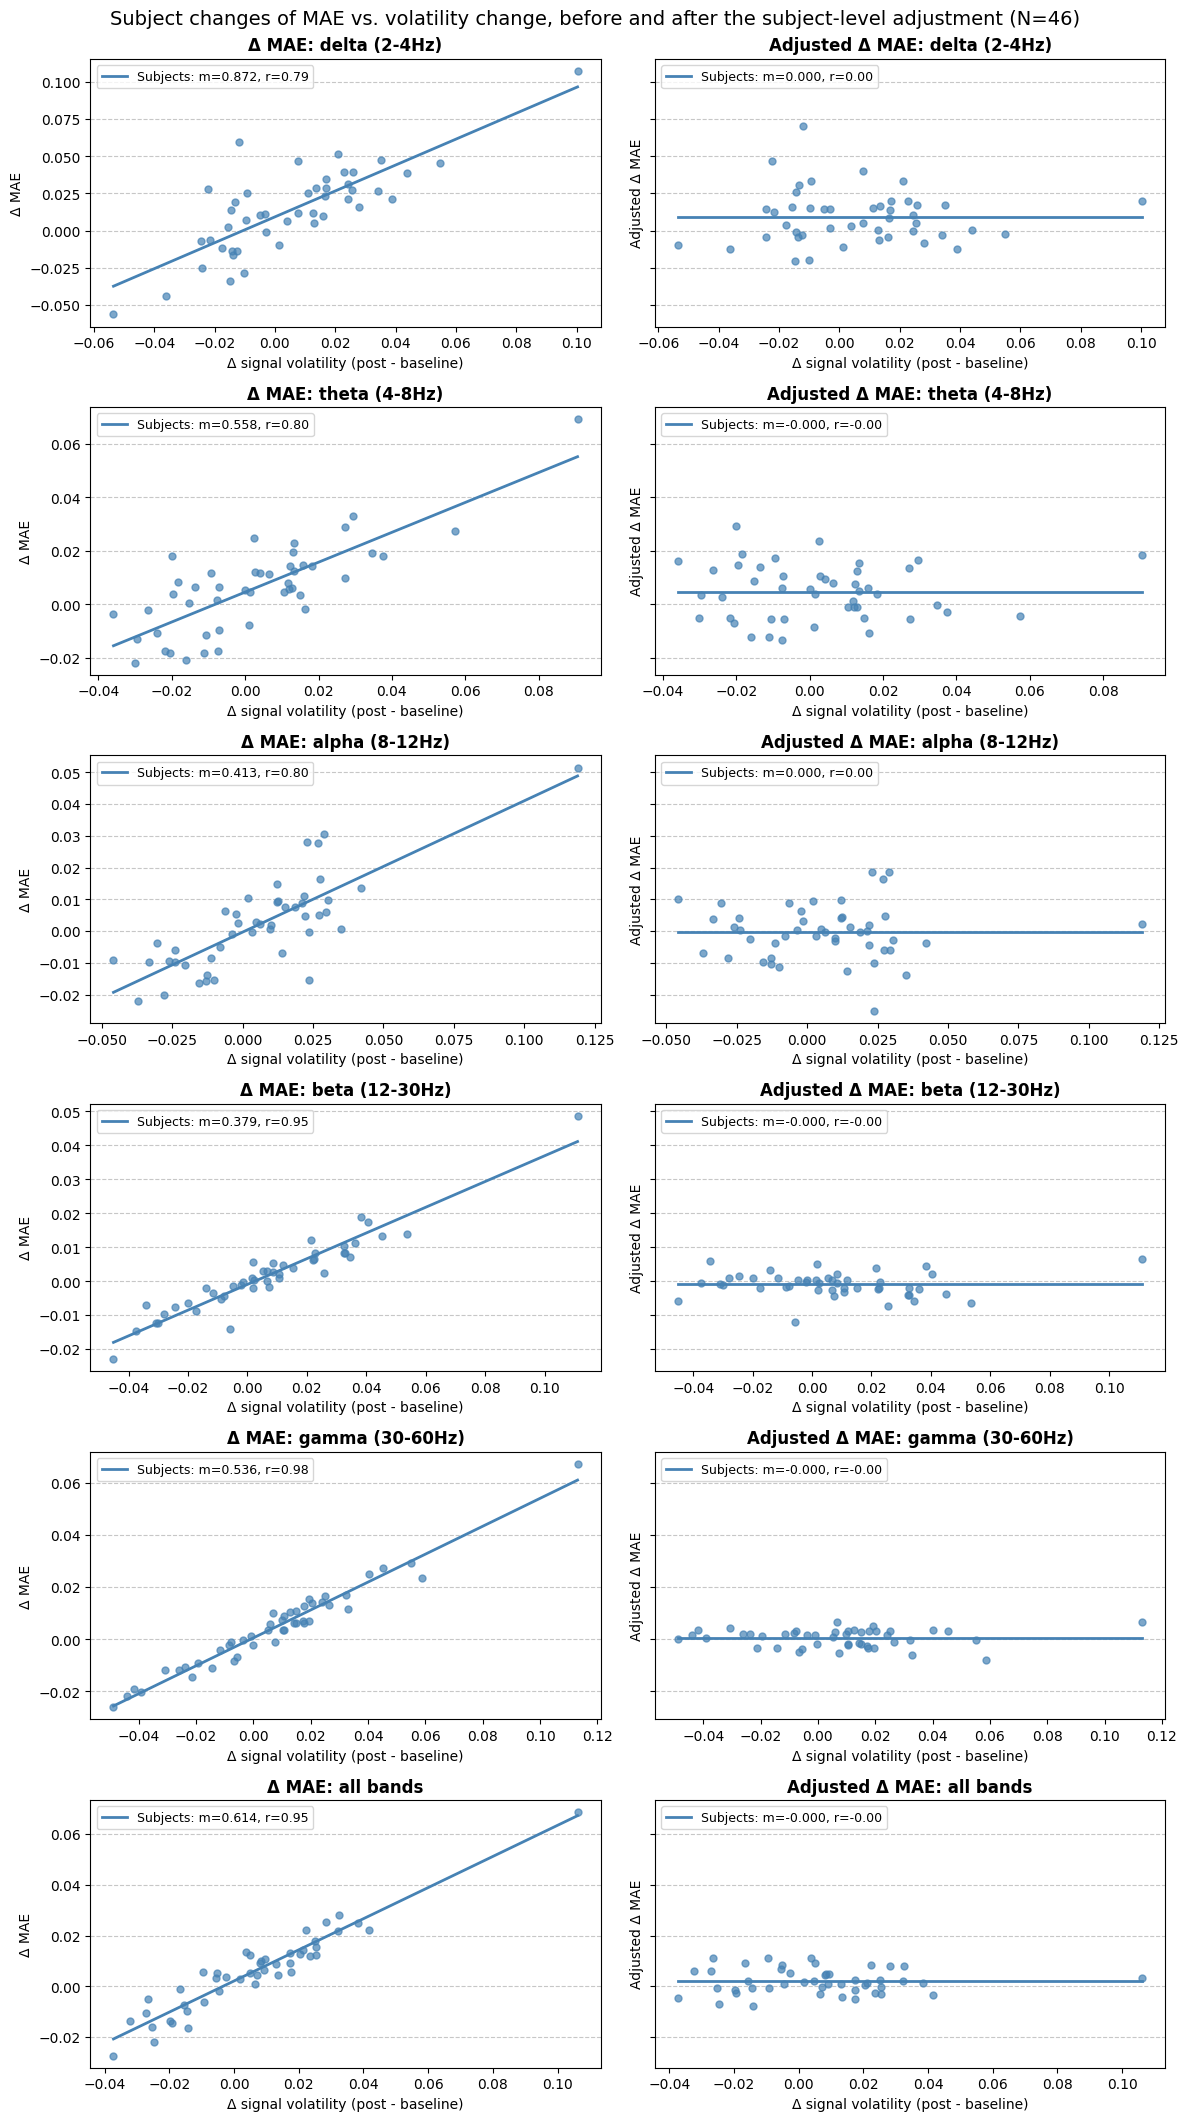

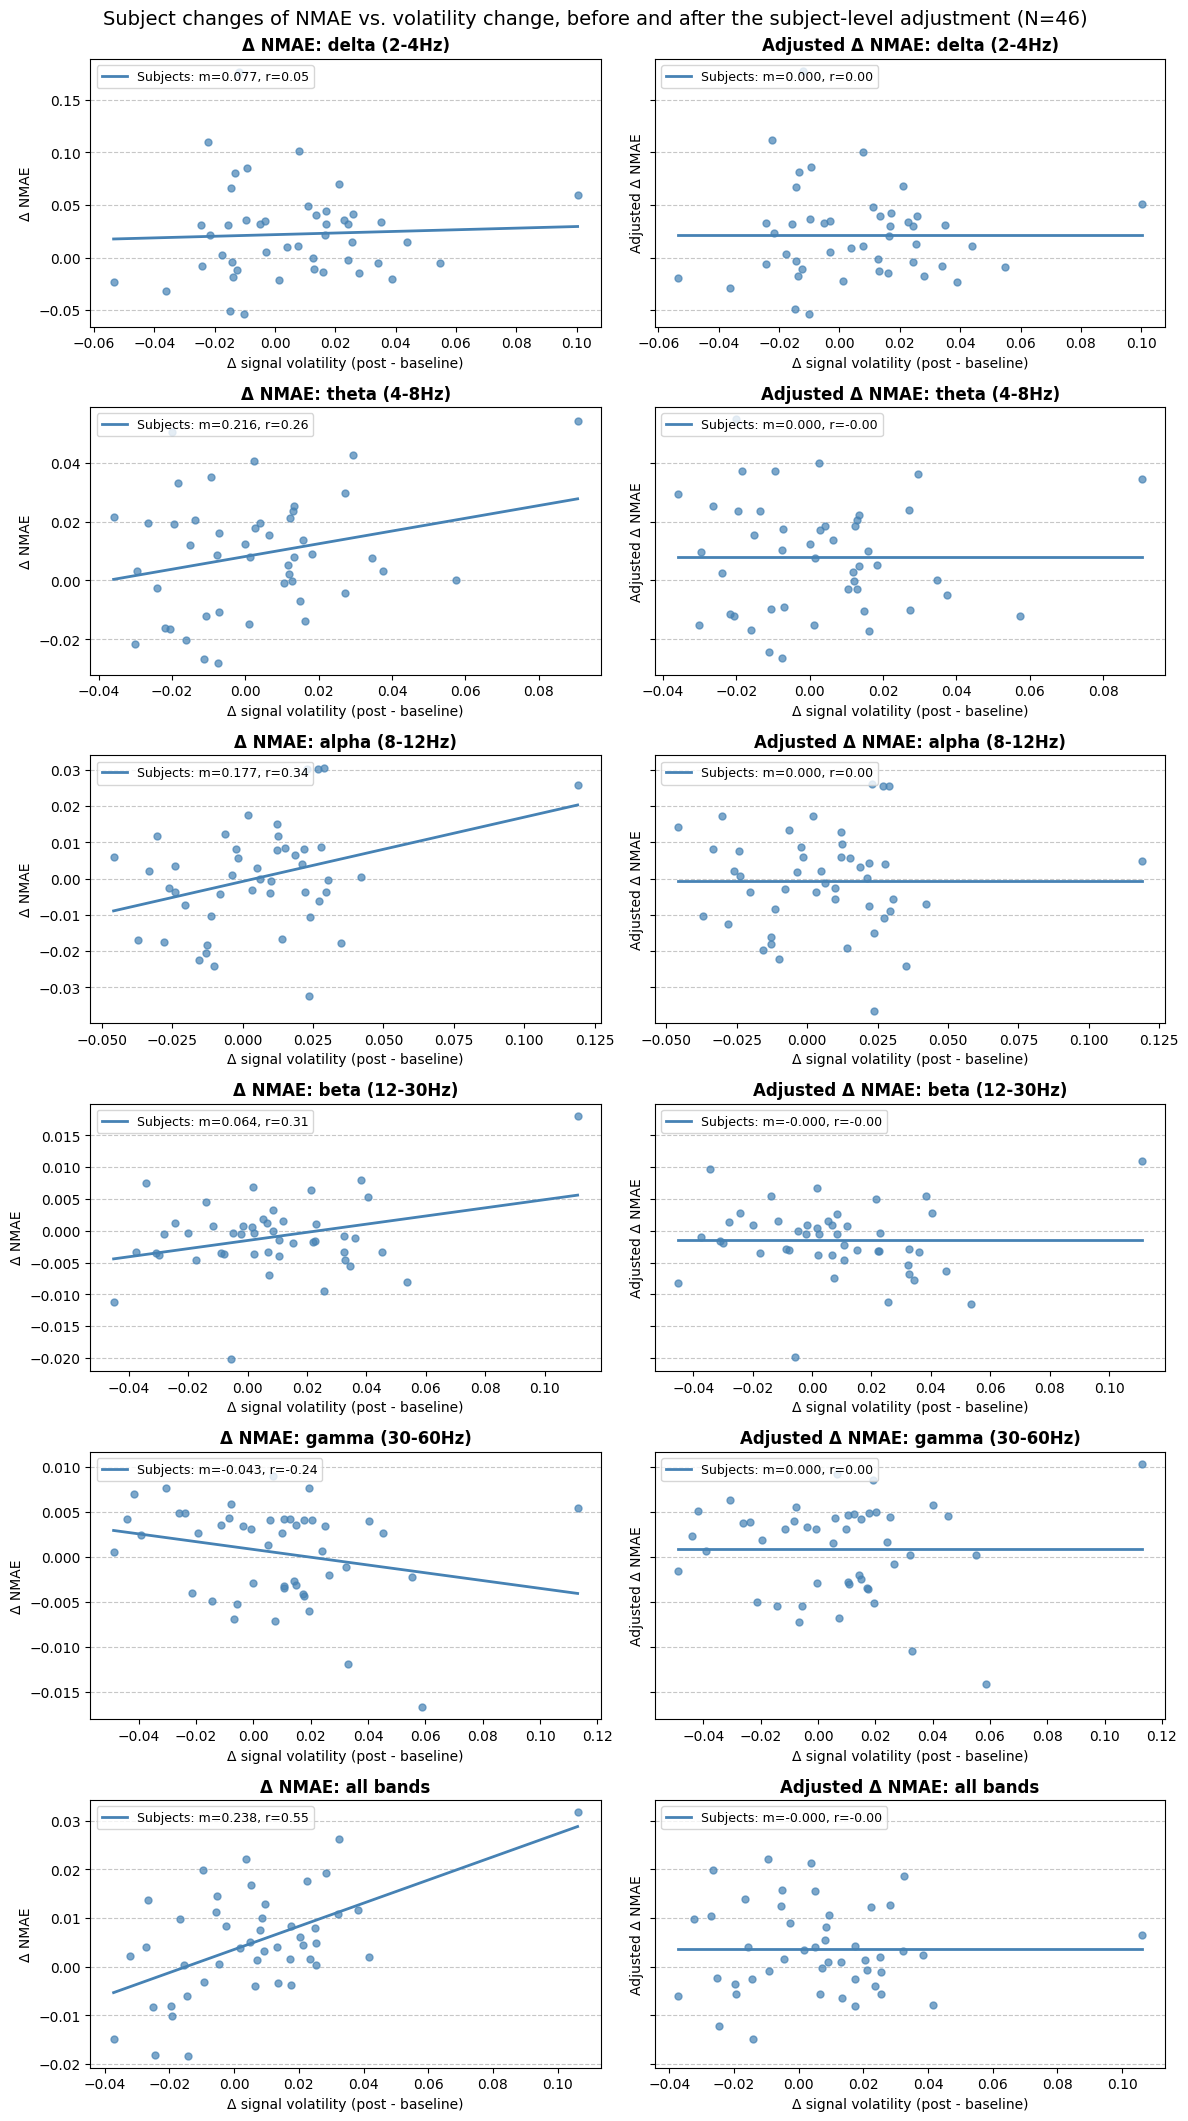

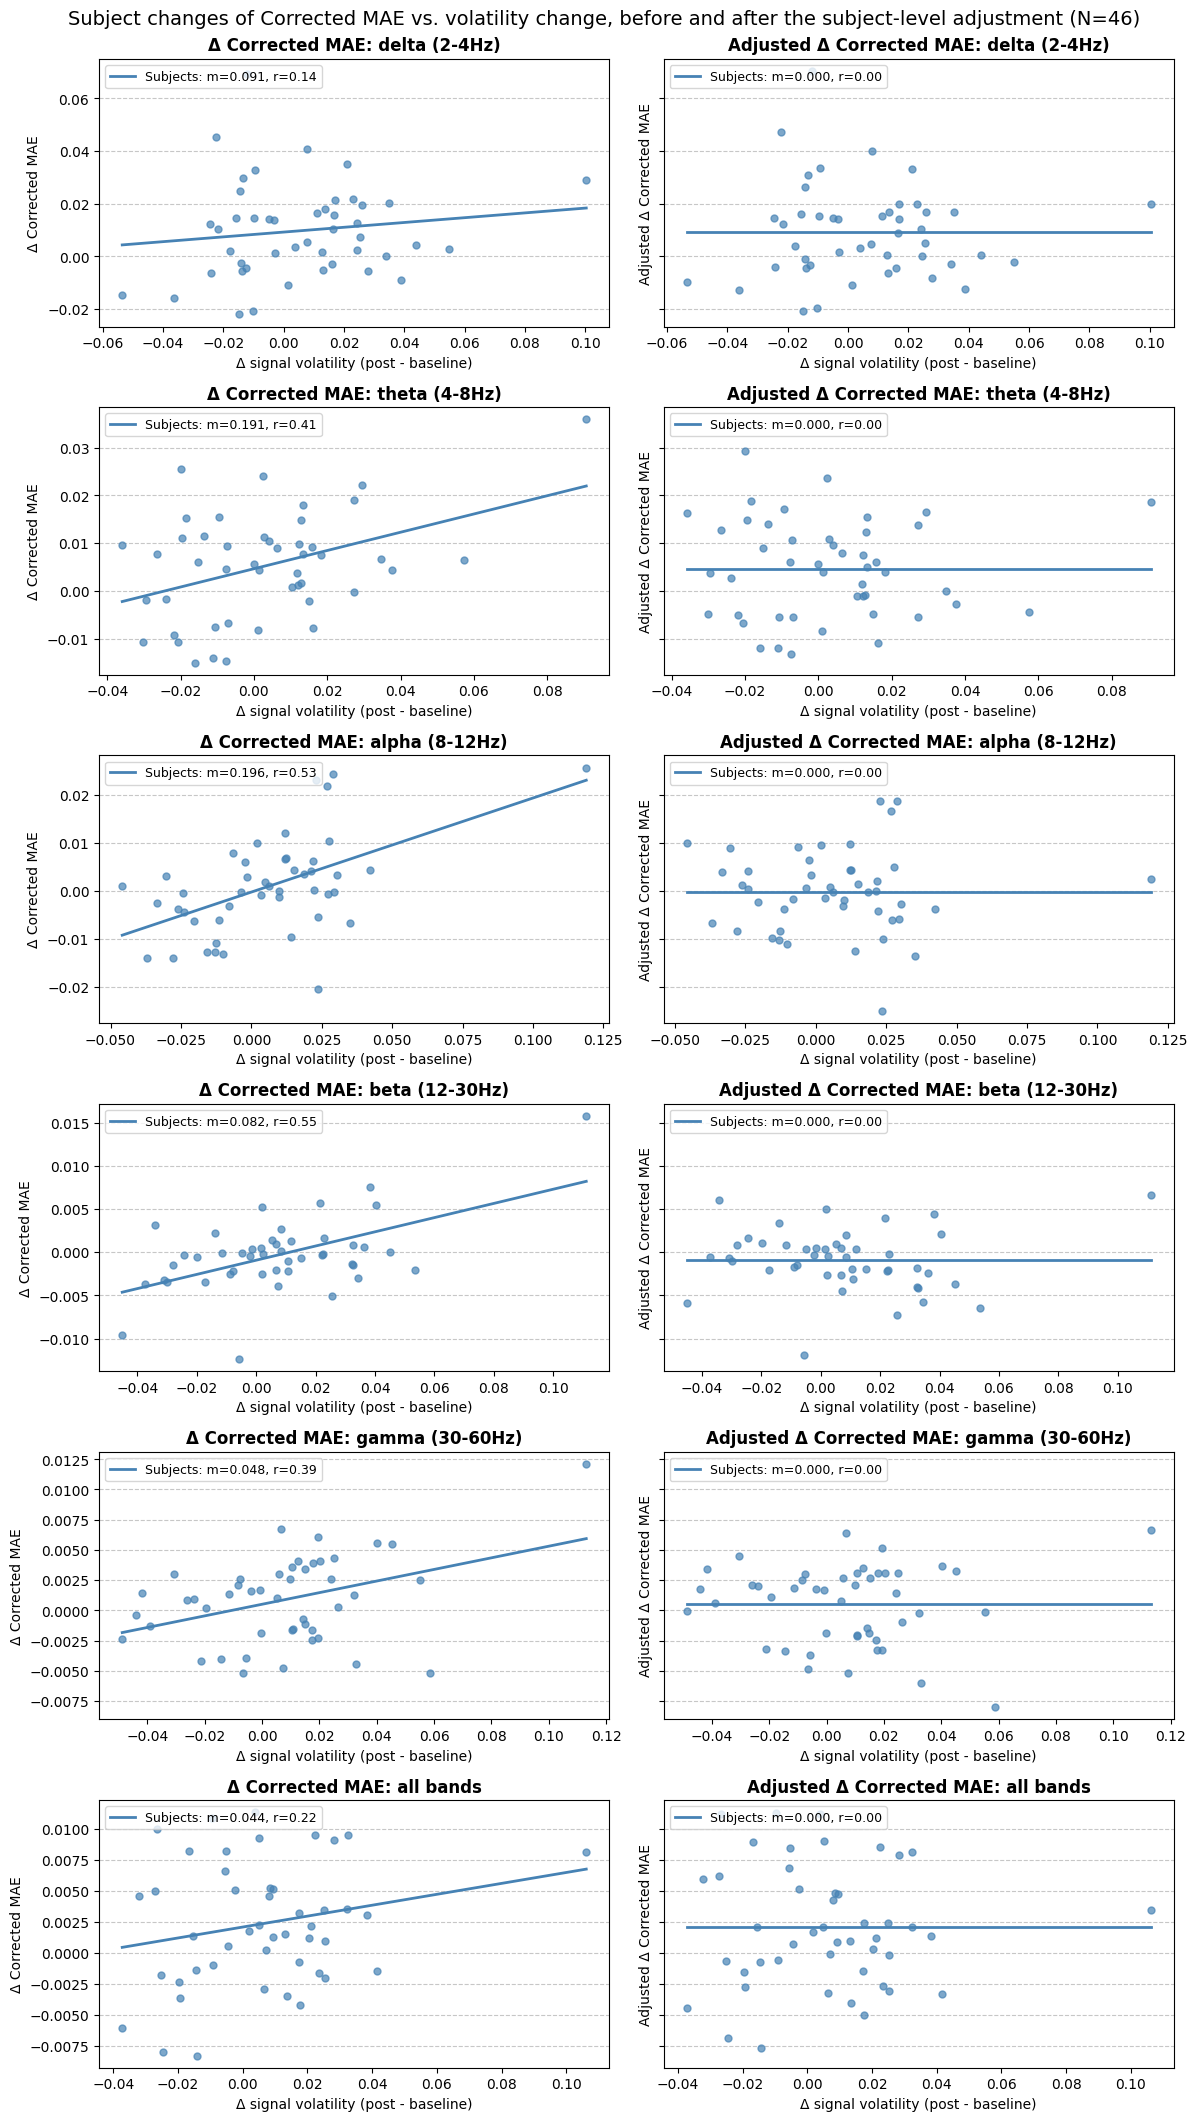

In [209]:
b_vol_means, _ = data_processor.calc_subjectwise_metric_stats(baseline_merged, bands, "signal_volatility")
p_vol_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, "signal_volatility")

for label, metric in metrics_to_compare.items():
    b_means, p_adjusted, _ = data_processor.calc_subject_adjusted_metric(baseline_merged, postpatch_merged, metric, bands)
    p_means, _ = data_processor.calc_subjectwise_metric_stats(postpatch_merged, bands, metric)
    subjects = list(b_means.keys())
    vol_changes = {b: [p_vol_means[s][b] - b_vol_means[s][b] for s in subjects] for b in band_keys}
    metric_changes = {b: [p_means[s][b] - b_means[s][b] for s in subjects] for b in band_keys}
    adjusted_changes = {b: [p_adjusted[s][b] - b_means[s][b] for s in subjects] for b in band_keys}

    plotting.session_correlation_plot(x_by_session={"Subjects": vol_changes},
                                      y_by_metric={f"Δ {label}": {"Subjects": metric_changes}, f"Adjusted Δ {label}": {"Subjects": adjusted_changes}},
                                      xlabel="Δ signal volatility (post - baseline)", point_size=25, point_alpha=0.7,
                                      title=f"Subject changes of {label} vs. volatility change, before and after the subject-level adjustment (N={len(subjects)})",
                                      save_dir=plot_root / "subject_adjustment", save_name=f"{metric}_subject_adjustment_{an_suffix}_{excl_suffix}")


### Change after patching before and after the subject-level adjustment
Left: raw change of the subject means (`raw_changes` from the cell "Change of MAE, NMAE and corrected MAE after patching" above). Right: change of the adjusted subject means (`calc_subject_adjusted_metric`).
Both are mean ± SEM of the subject differences in % of the mean baseline value of each metric, with a paired t-test. The adjusted test treats the fitted slope as known, so its p-values are marginally optimistic.
The three metrics disagree before the adjustment and agree after it. Note that adjusted MAE and adjusted corrected MAE are identical by construction: the trial-level correction subtracts a linear function of volatility, which the subject-level fit absorbs into its slope. The agreement with NMAE (a ratio, not a linear correction) is the independent check that the adjusted result doesn't depend on the choice of metric.

Raw
  band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
  delta (2-4Hz)    |             +4.16  0.002 |             +2.79  0.001 |             +2.84  0.001
  theta (4-8Hz)    |             +2.69  0.016 |             +2.05  0.004 |             +2.23  0.003
  alpha (8-12Hz)   |             +1.16  0.322 |             +0.08  0.907 |             +0.46  0.576
  beta (12-30Hz)   |             +0.92  0.254 |             -0.31  0.226 |             -0.15  0.619
  gamma (30-60Hz)  |             +1.20  0.071 |             +0.09  0.523 |             +0.23  0.115
  all bands        |             +2.15  0.020 |             +1.06  0.003 |             +0.87  0.003
Volatility-adjusted
  band             |             MAE %      p |            NMAE %      p |   Corrected MAE %      p
  delta (2-4Hz)    |             +2.69  0.001 |             +2.73  0.001 |             +2.69  0.001
  theta (4-8Hz)    |             +1.99  0.004 |             +1.90  0.006 |  

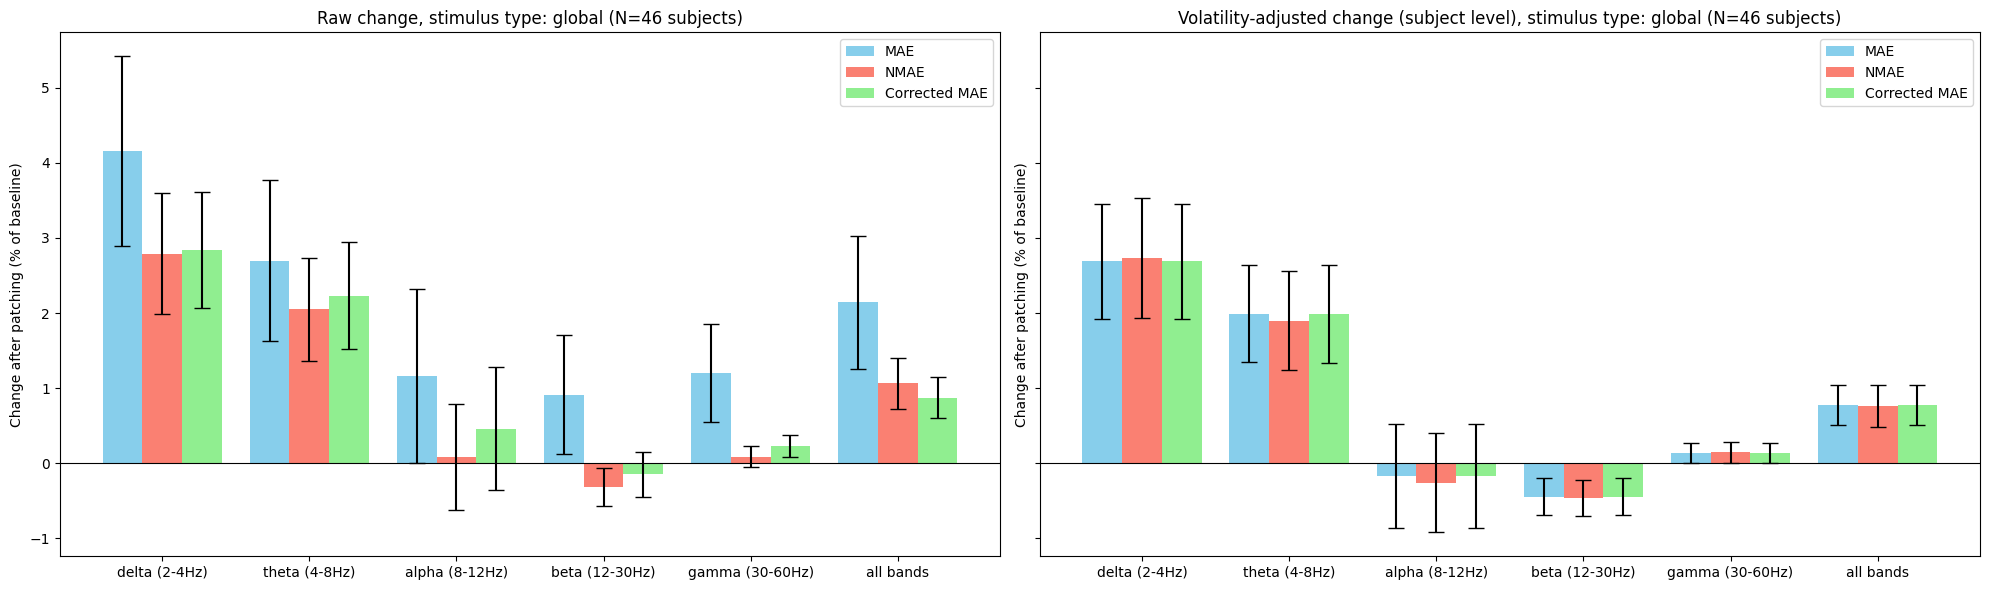

In [210]:
# adjusted change of the subject means per metric, same statistics as raw_changes
adjusted_changes_by_metric = {}
for label, metric in metrics_to_compare.items():
    b_means, p_adjusted, _ = data_processor.calc_subject_adjusted_metric(baseline_merged, postpatch_merged, metric, bands)
    subjects = list(b_means.keys())
    pre = np.array([[b_means[s][b] for b in band_keys] for s in subjects])
    post = np.array([[p_adjusted[s][b] for b in band_keys] for s in subjects])
    scale = 100 / pre.mean(axis=0)
    adjusted_changes_by_metric[label] = ((post - pre).mean(axis=0) * scale, sem(post - pre) * scale, ttest_rel(post, pre).pvalue)

for title, changes_by_metric in [("Raw", raw_changes), ("Volatility-adjusted", adjusted_changes_by_metric)]:
    print(title)
    print(f"  {'band':16s}" + "".join(f" | {label + ' %':>17s} {'p':>6s}" for label in changes_by_metric))
    for i, band in enumerate(band_keys):
        print(f"  {band:16s}" + "".join(f" | {changes[i]:+17.2f} {ps[i]:6.3f}" for changes, _, ps in changes_by_metric.values()))

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharey=True)
for ax, (title, changes_by_metric) in zip(axes, [("Raw change", raw_changes), ("Volatility-adjusted change (subject level)", adjusted_changes_by_metric)]):
    plotting.plot_grouped_bar(x_text=band_keys, width=0.27, means=[changes for changes, _, _ in changes_by_metric.values()],
                              sems=[sems for _, sems, _ in changes_by_metric.values()], labels=list(changes_by_metric.keys()),
                              title=f'{title}, stimulus type: {", ".join(conditions)}', y_label="Change after patching (% of baseline)",
                              n_text=f"N={len(subjects)} subjects", ax=ax, fig=fig)
    ax.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plotting.save_button(fig, save_dir=plot_root / "subject_adjustment", default_name=f"subject_adjustment_difference_{an_suffix}_{excl_suffix}")
plt.show()
